### Load Data from the-verdict.txt

In [1]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()
    
print("Total number of character:", len(raw_text))
print(raw_text[:99])

Total number of character: 20481
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


### Text tokenize

In [2]:
import re

text = "Hello, My name is Bin. I'm from Cau Nhi, Hai Tan, Hai Lang, Quang Tri"

result = re.split(r'(\s)', text)

print(result)

['Hello,', ' ', 'My', ' ', 'name', ' ', 'is', ' ', 'Bin.', ' ', "I'm", ' ', 'from', ' ', 'Cau', ' ', 'Nhi,', ' ', 'Hai', ' ', 'Tan,', ' ', 'Hai', ' ', 'Lang,', ' ', 'Quang', ' ', 'Tri']


- nếu case yêu cầu tách dấu ra

In [3]:
result = re.split(r'([,.]|\s)', text)

print(result)

['Hello', ',', '', ' ', 'My', ' ', 'name', ' ', 'is', ' ', 'Bin', '.', '', ' ', "I'm", ' ', 'from', ' ', 'Cau', ' ', 'Nhi', ',', '', ' ', 'Hai', ' ', 'Tan', ',', '', ' ', 'Hai', ' ', 'Lang', ',', '', ' ', 'Quang', ' ', 'Tri']


In [4]:
text = "Hello, world. Is this-- a test?"
result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
print(result)
result = [token.strip() for token in result if token.strip() != '']
print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'Is', ' ', 'this', '--', '', ' ', 'a', ' ', 'test', '?', '']
['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


This is pretty good, and we are now ready to apply this tokenization to the raw text  

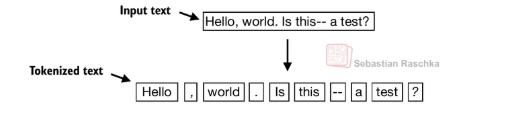

In [5]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [token.strip() for token in preprocessed if token.strip() != '']

print ("Total number of tokens:", len(preprocessed))
print ("First 100 tokens:", preprocessed[:30]) 

Total number of tokens: 4690
First 100 tokens: ['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


## 2.3 Converting tokens into token IDs

In [10]:
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)

print(vocab_size)

1130


In [11]:
vocab = {token:integer for integer,token in enumerate(all_words)}

In [12]:
for i, item in enumerate(vocab.items()):
    print(item)
    if i >= 50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


In [6]:
class SimpleTokennizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s, i in vocab.items()}
        
    def encode(self, text):
        tokens = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        tokens = [token.strip() for token in tokens if token.strip() != '']
        return [self.str_to_int[token] for token in tokens if token in self.str_to_int]
    
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # remove space before punctuation
        text = re.sub(r'\s([,.:;?_!"()\'])', r'\1', text)
        return text
        

In [15]:
tokenizer = SimpleTokennizerV1(vocab)

text = """"It's the last he painted, you know," 
           Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [16]:
tokenizer.decode(ids)

'" It\' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.'

It's useful to add some "special" tokens for unknown words and to denote the end of a text

Some tokenizers use special tokens to help the LLM with additional context

Some of these special tokens are

[BOS] (beginning of sequence) marks the beginning of text
[EOS] (end of sequence) marks where the text ends (this is usually used to concatenate multiple unrelated texts, e.g., two different Wikipedia articles or two different books, and so on)
[PAD] (padding) if we train LLMs with a batch size greater than 1 (we may include multiple texts with different lengths; with the padding token we pad the shorter texts to the longest length so that all texts have an equal length)
[UNK] to represent words that are not included in the vocabulary

Note that GPT-2 does not need any of these tokens mentioned above but only uses an <|endoftext|> token to reduce complexity

The <|endoftext|> is analogous to the [EOS] token mentioned above

GPT also uses the <|endoftext|> for padding (since we typically use a mask when training on batched inputs, we would not attend padded tokens anyways, so it does not matter what these tokens are)

GPT-2 does not use an <UNK> token for out-of-vocabulary words; instead, GPT-2 uses a byte-pair encoding (BPE) tokenizer, which breaks down words into subword units which we will discuss in a later section

We use the <|endoftext|> tokens between two independent sources of text:

Let's see what happens if we tokenize the following text:

In [17]:
tokenizer = SimpleTokenizerV1(vocab)

text = "Hello, do you like tea. Is this-- a test?"

tokenizer.encode(text)

NameError: name 'SimpleTokenizerV1' is not defined

In [18]:
all_tokens = sorted(set(preprocessed))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])

vocab = {token:integer for integer,token in enumerate(all_tokens)}



In [19]:
len(vocab.items())

1132

In [20]:
for i, item in enumerate(vocab.items()):
    print(item)
    if i >= 50:
        break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


In [21]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s, i in vocab.items()}
        
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        preprocessed = [
            item if item in self.str_to_int 
            else "<|unk|>" for item in preprocessed
        ]

        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        # remove space before punctuation
        text = re.sub(r'\s([,.:;?_!"()\'])', r'\1', text)
        return text

In [22]:

tokenizer = SimpleTokenizerV2(vocab)

text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."

text = " <|endoftext|> ".join((text1, text2))

print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


In [23]:
tokenizer.encode(text)


[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]

In [24]:
tokenizer.decode(tokenizer.encode(text))

'<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.'

### BytePair Encoding BPE
- GPT-2 used BytePair encoding (BPE) as its tokenizer
- it allows the model to break down words that aren't in its predefined vocabulary into smaller subword units or even individual characters, enabling it to handle out-of-vocabulary words
- For instance, if GPT-2's vocabulary doesn't have the word "unfamiliarword," it might tokenize it as ["unfam", "iliar", "word"] or some other subword breakdown, depending on its trained BPE merges
- The original BPE tokenizer can be found here: https://github.com/openai/gpt-2/blob/master/src/encoder.py
- In this chapter, we are using the BPE tokenizer from OpenAI's open-source tiktoken library, which implements its core algorithms in Rust to improve computational performance
- I created a notebook in the ./bytepair_encoder that compares these two implementations side-by-side (tiktoken was about 5x faster on the sample text)

In [27]:
import importlib
import tiktoken

print("tiktoken version:", importlib.metadata.version("tiktoken"))

tiktoken version: 0.14.0


In [28]:
tokenizer = tiktoken.get_encoding("gpt2")

In [31]:
text = (
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
     "of someunknownPlace."
)

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


In [32]:
strings = tokenizer.decode(integers)

print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


### Data sampling with a sliding window

In [33]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print("Total number of tokens:", len(enc_text))

Total number of tokens: 5146


In [34]:
enc_sample = enc_text[50:]

In [38]:
context_size = 4

x = enc_sample[:context_size]
y = enc_sample[1:context_size + 1]

print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


- One by one, the prediction would look like as follows:

- ý nó là cho i thì dự đoán i + 1 
- như là tôi ----> thích 
  - tôi thích ----> câu
    - tôi thích câu ----> cá

In [39]:
for i in range(1, context_size +1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    
    print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


In [ ]:
import torch
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


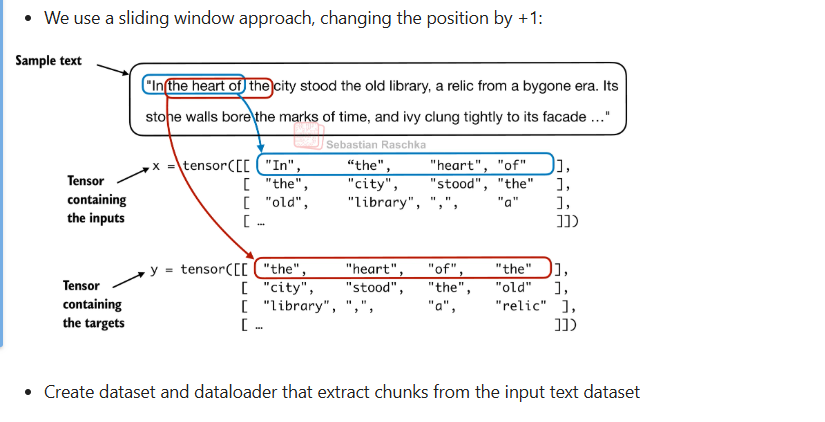

In [ ]:
from torch.utils.data import Dataset, DataLoader


class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        # Tokenize the entire text
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        # if đè tem assert
        assert len(token_ids) > max_length, "Number of tokenized inputs must at least be equal to max_length+1"

        # Use a sliding window to chunk the book into overlapping sequences of max_length
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [52]:
def create_dataloader_v1(txt, batch_size=4, max_length=256, 
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):

    # Initialize the tokenizer
    tokenizer = tiktoken.get_encoding("gpt2")

    # Create dataset
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    # Create dataloader
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

In [53]:

with open("the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

In [54]:
dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)

data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


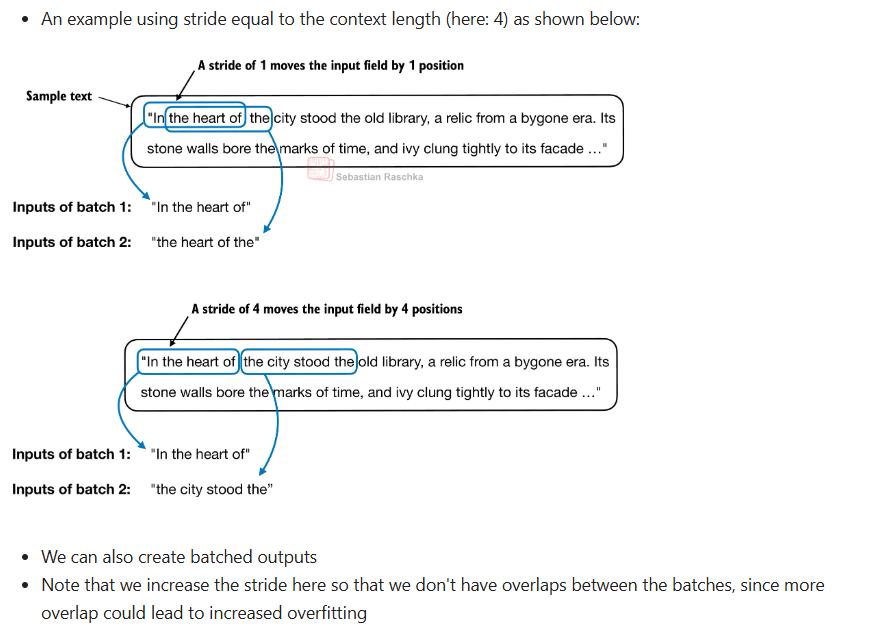

In [56]:
dataloader = create_dataloader_v1(raw_text, batch_size=8, max_length=4, stride=4, shuffle=False)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)


Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


### Creating token embeddings

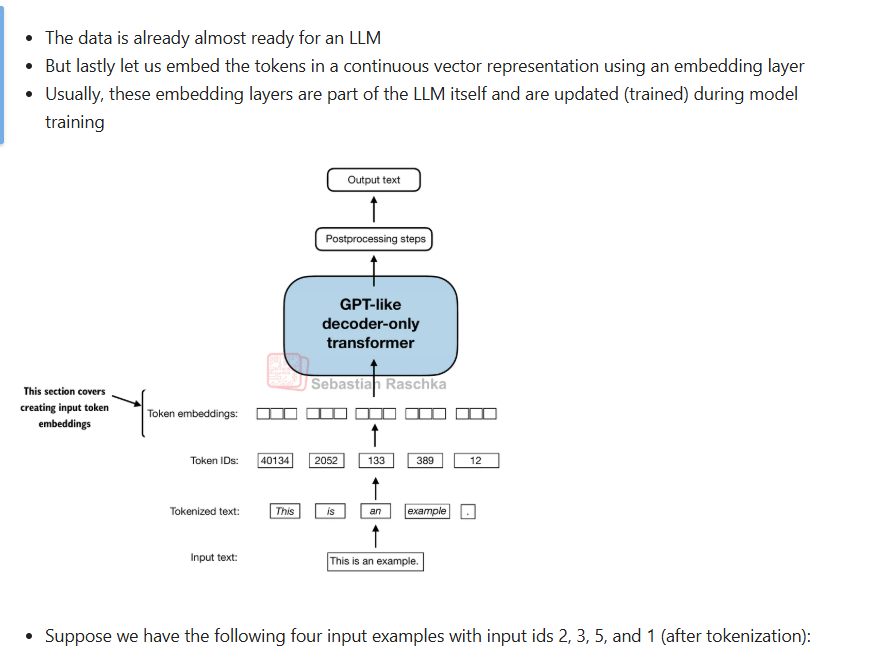

In [57]:
input_ids = torch.tensor([2,3,5,1])

In [58]:
vocab_size = 6
output_dim = 3

torch.manual_seed(42)
embedding_layer = torch.nn.Embedding(num_embeddings=vocab_size, embedding_dim=output_dim)

In [59]:
print(embedding_layer.weight)


Parameter containing:
tensor([[ 1.9269,  1.4873, -0.4974],
        [ 0.4396, -0.7581,  1.0783],
        [ 0.8008,  1.6806,  0.3559],
        [-0.6866,  0.6105,  1.3347],
        [-0.2316,  0.0418, -0.2516],
        [ 0.8599, -0.3097, -0.3957]], requires_grad=True)


In [60]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.6866,  0.6105,  1.3347]], grad_fn=<EmbeddingBackward0>)


In [61]:
print(embedding_layer(input_ids))

tensor([[ 0.8008,  1.6806,  0.3559],
        [-0.6866,  0.6105,  1.3347],
        [ 0.8599, -0.3097, -0.3957],
        [ 0.4396, -0.7581,  1.0783]], grad_fn=<EmbeddingBackward0>)


### Encoding word positions

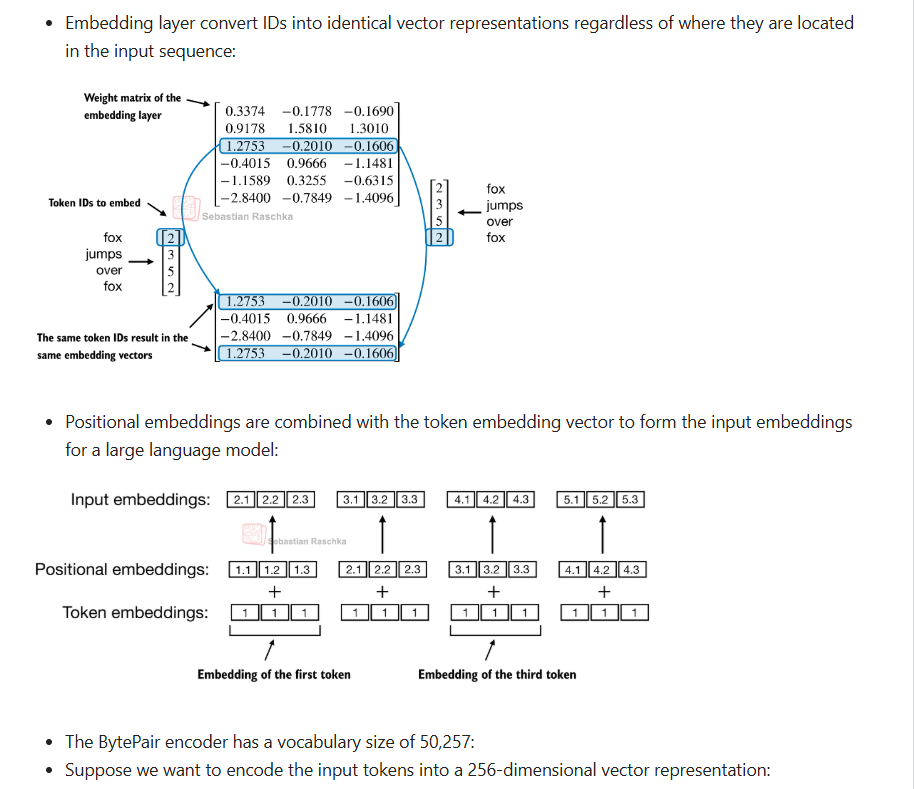

In [62]:
vocab_size = 50257
output_dim = 256

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [63]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)

In [64]:

print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


In [65]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

print(token_embeddings)

torch.Size([8, 4, 256])
tensor([[[-0.2263,  1.5471,  1.7993,  ..., -1.0731, -0.6847, -1.1511],
         [ 0.0424,  0.6706,  3.0505,  ...,  1.7153,  0.1248,  0.5104],
         [-0.0822,  0.2824, -0.0252,  ..., -1.3636,  0.8076, -0.5555],
         [-0.3119, -0.5069,  0.6564,  ...,  0.4261, -0.6862,  0.1792]],

        [[-0.8024, -0.5311,  0.3413,  ..., -0.6746, -0.5287,  0.4826],
         [-0.9617, -1.3067,  0.9604,  ...,  0.5882,  0.1146,  1.2057],
         [ 0.2523, -1.1060, -0.1456,  ..., -0.2607, -0.2119,  1.3098],
         [-0.7337, -0.7522, -1.2087,  ..., -0.9394, -0.7060, -1.2497]],

        [[ 0.8874,  1.4040, -0.4347,  ..., -0.9425, -1.2974, -0.7004],
         [ 1.5277,  1.2768,  0.5495,  ...,  0.2221, -1.1950, -0.1272],
         [ 1.2257,  0.2031,  1.3164,  ...,  0.2771, -0.5194, -0.0842],
         [-1.0515, -1.1439,  1.4062,  ..., -0.1213, -0.8012, -0.2967]],

        ...,

        [[ 0.4443, -0.6204, -0.3772,  ..., -0.9612,  1.7805,  2.2842],
         [-0.4500,  1.3793, -0.42

In [66]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

print(pos_embedding_layer.weight)

Parameter containing:
tensor([[ 1.2192, -0.2741,  0.6823,  ..., -2.0313, -0.3160, -0.2499],
        [ 0.1600, -2.1962,  0.4126,  ..., -1.1532,  0.4579,  1.3812],
        [-0.1451,  0.5679,  0.1859,  ...,  0.2771, -1.2594,  1.3905],
        [ 1.3473, -0.5042, -0.2962,  ...,  0.7891,  1.0097, -0.0340]],
       requires_grad=True)


In [67]:
pos_embeddings = pos_embedding_layer(torch.arange(max_length))
print(pos_embeddings.shape)

print(pos_embeddings)

torch.Size([4, 256])
tensor([[ 1.2192, -0.2741,  0.6823,  ..., -2.0313, -0.3160, -0.2499],
        [ 0.1600, -2.1962,  0.4126,  ..., -1.1532,  0.4579,  1.3812],
        [-0.1451,  0.5679,  0.1859,  ...,  0.2771, -1.2594,  1.3905],
        [ 1.3473, -0.5042, -0.2962,  ...,  0.7891,  1.0097, -0.0340]],
       grad_fn=<EmbeddingBackward0>)


In [68]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

print(input_embeddings)

torch.Size([8, 4, 256])
tensor([[[ 0.9929,  1.2730,  2.4816,  ..., -3.1044, -1.0006, -1.4009],
         [ 0.2024, -1.5256,  3.4631,  ...,  0.5621,  0.5827,  1.8916],
         [-0.2273,  0.8504,  0.1607,  ..., -1.0865, -0.4518,  0.8350],
         [ 1.0354, -1.0111,  0.3602,  ...,  1.2152,  0.3235,  0.1452]],

        [[ 0.4168, -0.8053,  1.0236,  ..., -2.7059, -0.8447,  0.2327],
         [-0.8017, -3.5029,  1.3730,  ..., -0.5651,  0.5725,  2.5869],
         [ 0.1072, -0.5381,  0.0403,  ...,  0.0164, -1.4713,  2.7003],
         [ 0.6136, -1.2564, -1.5048,  ..., -0.1503,  0.3037, -1.2837]],

        [[ 2.1066,  1.1299,  0.2476,  ..., -2.9739, -1.6134, -0.9502],
         [ 1.6877, -0.9194,  0.9621,  ..., -0.9311, -0.7371,  1.2539],
         [ 1.0806,  0.7711,  1.5023,  ...,  0.5542, -1.7788,  1.3063],
         [ 0.2958, -1.6481,  1.1100,  ...,  0.6679,  0.2085, -0.3307]],

        ...,

        [[ 1.6635, -0.8945,  0.3051,  ..., -2.9925,  1.4646,  2.0344],
         [-0.2900, -0.8169, -0.01